In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

# Loading Dataset

In [2]:
iris_dataset = load_iris()
df = pd.DataFrame(iris_dataset.data)
df.columns = iris_dataset.feature_names
df['target'] = iris_dataset.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [3]:
# or read in data from a csv!
df = pd.read_csv('/kaggle/input/iris-csv/iris.csv', index_col=0)
df['target'] = iris_dataset.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


### Cleaning Dataset

In [4]:
# check which rows contain a null value...
df[df.isnull().any(axis=1)]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
24,NaN,3.4,1.9,0.2,0
37,4.9,3.6,NaN,0.1,0
56,6.3,NaN,4.7,1.6,1


In [5]:
# ...and drop 'em
df = df.dropna()
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


### Visualizing Dataset

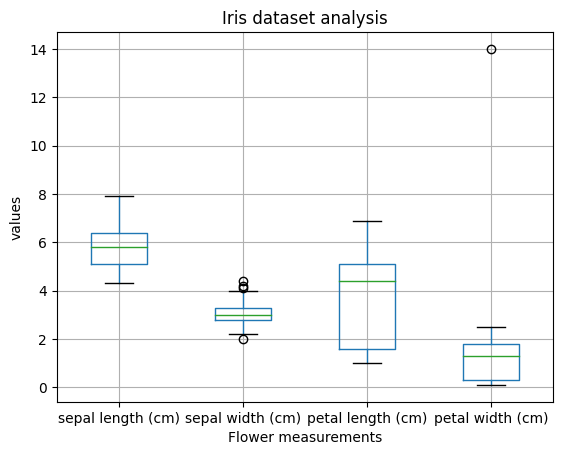

In [6]:
# let's visualize some stuffs
df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']].boxplot()
plt.xlabel("Flower measurements")
plt.ylabel("values")
plt.title("Iris dataset analysis")
plt.show()

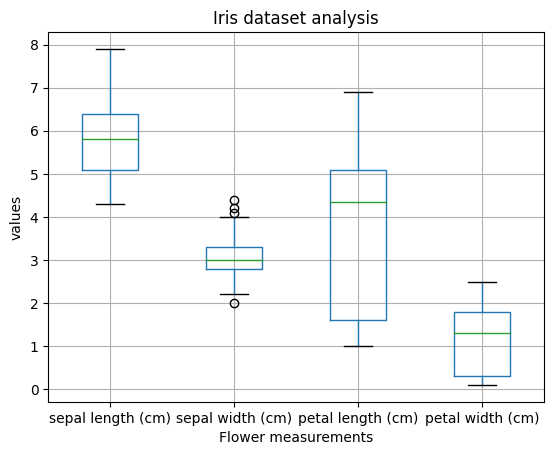

In [7]:
# drop outlier row and re-visualize
df = df[df["petal width (cm)"] < 14]

# or we could replace the 14 value with 1.4. two ways to do this:
# df = df.replace(to_replace=14, value=1.4)
# df.replace(to_replace=14, value=1.4, inplace=True

df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']].boxplot()
plt.xlabel("Flower measurements")
plt.ylabel("values")
plt.title("Iris dataset analysis")
plt.show()

<Axes: ylabel='Frequency'>

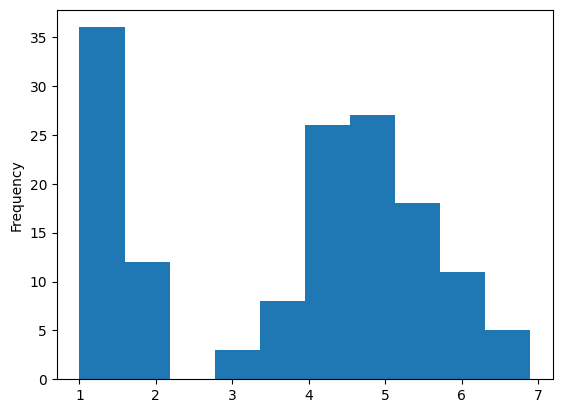

In [8]:
# here's a histogram:
df['petal length (cm)'].plot.hist()

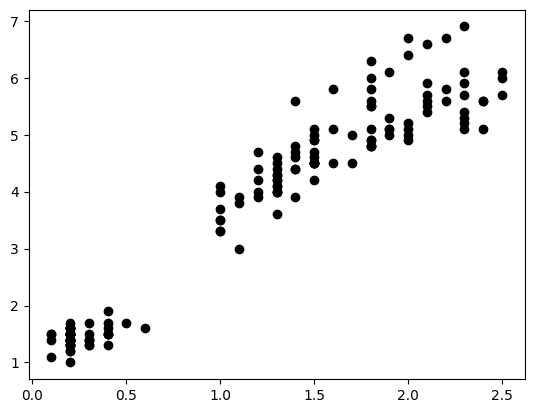

In [9]:
# let's make a scatter plot
x = df['petal width (cm)']
y = df['petal length (cm)']

# converting to numopy arrays with 1 col
x = x.values.reshape(-1, 1)
y = y.values.reshape(-1, 1)

# and then we plot!
plt.scatter(x, y, c='black')

### Feature Extraction

In [10]:
# grady is crazy and really likes apply functions

# cutoff = 2.5
# df['petal_class'] = df['petal length (cm)'].apply(lambda x: 'long' if x > cutoff else 'short')
# df

In [11]:
cutoff = 2.5
df['petal_class'] = 'placeholder'
df['petal_class'][df['petal length (cm)'] > cutoff] = 'long'
df['petal_class'][df['petal length (cm)'] <= cutoff] = 'short'
df

/tmp/ipykernel_18/1321043260.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['petal_class'] = 'placeholder'
/tmp/ipykernel_18/1321043260.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,petal_class
0,5.1,3.5,1.4,0.2,0,short
1,4.9,3.0,1.4,0.2,0,short
2,4.7,3.2,1.3,0.2,0,short
3,4.6,3.1,1.5,0.2,0,short
4,5.0,3.6,1.4,0.2,0,short
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,long
146,6.3,2.5,5.0,1.9,2,long
147,6.5,3.0,5.2,2.0,2,long
148,6.2,3.4,5.4,2.3,2,long


In [12]:
# summary statistics for a dataset
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,146.000000,146.00000,146.000000,146.000000,146.000000
mean,5.845890,3.04863,3.773973,1.209589,1.013699
std,0.824799,0.43790,1.768500,0.761788,0.821993
min,4.300000,2.00000,1.000000,0.100000,0.000000
25%,5.100000,2.80000,1.600000,0.300000,0.000000
50%,5.800000,3.00000,4.350000,1.300000,1.000000
75%,6.400000,3.30000,5.100000,1.800000,2.000000
max,7.900000,4.40000,6.900000,2.500000,2.000000
